<a href="https://colab.research.google.com/github/ryanglenc/MAT_442/blob/main/MAT_442_3_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from scipy.optimize import minimize
np.set_printoptions(precision=4, suppress=True)
np.random.seed(42069)

## 3.3.1 Necessary and Sufficient Conditions of Local Minimizers

For a twice continuously differentiable function f, a point x* is a **local minimizer** only if it satisfies:

- **First-order necessary condition:** ∇f(x*) = 0 (x* is a critical point).
- **Second-order necessary condition:** the Hessian ∇²f(x*) is positive semidefinite (all eigenvalues ≥ 0).

A critical point is guaranteed to be a strict local minimizer if:

- **Second-order sufficient condition:** ∇f(x*) = 0 and ∇²f(x*) is positive definite (all eigenvalues > 0).

The conditions are not equivalent. For example, f(x) = x³ has f'(0) = 0 and f''(0) = 0 (the necessary conditions hold), but 0 is not a minimizer.

We'll use SymPy to find the critical points of f(x, y) = x³ - 3x + y², classify each using the Hessian eigenvalues, and then check the result numerically.

In [10]:
x, y = sp.symbols('x y', real=True)
f_sym = x**3 - 3*x + y**2

grad_sym = [sp.diff(f_sym, v) for v in (x, y)]
H_sym = sp.hessian(f_sym, (x, y))

print("Gradient:", grad_sym)
print("Hessian:", H_sym)

# First-order condition: solve grad f = 0
critical_points = sp.solve(grad_sym, (x, y), dict=True)
print("\nCritical points:", critical_points)

f_num = sp.lambdify((x, y), f_sym, 'numpy')

# Second-order analysis at each critical point
for pt in critical_points:
    H = np.array(H_sym.subs(pt).tolist(), dtype=float)
    eigs = np.linalg.eigvalsh(H)

    if np.all(eigs > 0):
        kind = "strict local minimizer (Hessian positive definite)"
    elif np.all(eigs < 0):
        kind = "local maximizer (Hessian negative definite)"
    elif np.any(eigs > 0) and np.any(eigs < 0):
        kind = "saddle point (Hessian indefinite), NOT a minimizer"
    else:
        kind = "inconclusive (Hessian singular)"

    print(f"\nPoint ({pt[x]}, {pt[y]}): Hessian eigenvalues = {eigs}")
    print("  ->", kind)

Gradient: [3*x**2 - 3, 2*y]
Hessian: Matrix([[6*x, 0], [0, 2]])

Critical points: [{x: -1, y: 0}, {x: 1, y: 0}]

Point (-1, 0): Hessian eigenvalues = [-6.  2.]
  -> saddle point (Hessian indefinite), NOT a minimizer

Point (1, 0): Hessian eigenvalues = [2. 6.]
  -> strict local minimizer (Hessian positive definite)


In [11]:
# Numerical check: sample small random perturbations around each critical point.
# At a true local minimizer, f should never decrease.
for pt in critical_points:
    p = np.array([float(pt[x]), float(pt[y])])
    f0 = f_num(*p)
    perturbs = 0.05 * np.random.randn(2000, 2)
    values = f_num(p[0] + perturbs[:, 0], p[1] + perturbs[:, 1])
    print(f"At ({p[0]:.0f}, {p[1]:.0f}): lowest nearby f - f(p) = {np.min(values) - f0:.6f}"
          f"  ({'never decreases -> consistent with minimizer' if np.min(values) >= f0 else 'decreases -> not a minimizer'})")

# Counterexample: necessary conditions hold but 0 is not a minimizer of x^3
g = lambda t: t**3
print("\nf(t) = t^3: f'(0) = 0 and f''(0) = 0, but")
print("  f(-0.1) =", g(-0.1), "< f(0) = 0 < f(0.1) =", g(0.1))

At (-1, 0): lowest nearby f - f(p) = -0.094009  (decreases -> not a minimizer)
At (1, 0): lowest nearby f - f(p) = 0.000010  (never decreases -> consistent with minimizer)

f(t) = t^3: f'(0) = 0 and f''(0) = 0, but
  f(-0.1) = -0.0010000000000000002 < f(0) = 0 < f(0.1) = 0.0010000000000000002


## 3.3.2 Convexity and Global Minimizers

A function f is **convex** if for all points a, b and all t in [0, 1]:

f(t·a + (1-t)·b) ≤ t·f(a) + (1-t)·f(b)

For a twice-differentiable f, this is equivalent to the Hessian being positive semidefinite everywhere.

The key payoff: **for a convex function, every local minimizer is a global minimizer**, and ∇f(x*) = 0 is both necessary and sufficient. For a non-convex function, a local minimizer can be strictly worse than the global one.

We'll compare two examples:
1. A convex quadratic f(x) = ½ xᵀQx - bᵀx with Q positive definite. Its unique global minimizer solves Qx = b.
2. A non-convex function f(t) = t⁴ - 2t² + 0.5t, which has two local minimizers with different values.

In [12]:
# --- Example 1: convex quadratic ---
Q = np.array([[3.0, 1.0],
              [1.0, 2.0]])
b = np.array([1.0, 1.0])

f_quad = lambda v: 0.5 * v @ Q @ v - b @ v

print("Eigenvalues of Q:", np.linalg.eigvalsh(Q), "(all > 0, so the Hessian is positive definite)")

# Check the convexity inequality on many random pairs of points
violations = 0
for _ in range(5000):
    a_pt, b_pt = np.random.randn(2) * 5, np.random.randn(2) * 5
    t = np.random.rand()
    lhs = f_quad(t * a_pt + (1 - t) * b_pt)
    rhs = t * f_quad(a_pt) + (1 - t) * f_quad(b_pt)
    if lhs > rhs + 1e-9:
        violations += 1
print("Convexity inequality violations out of 5000:", violations)

# Global minimizer: solve Q x = b (grad f = Qx - b = 0)
x_star = np.linalg.solve(Q, b)
print("\nGlobal minimizer x* =", x_star, " f(x*) =", round(f_quad(x_star), 4))

# Different starting points all land on the same answer
for start in ([5, 5], [-4, 3], [0, -6]):
    res = minimize(f_quad, x0=start)
    print(f"  start {start} -> {res.x}")

Eigenvalues of Q: [1.382 3.618] (all > 0, so the Hessian is positive definite)
Convexity inequality violations out of 5000: 0

Global minimizer x* = [0.2 0.4]  f(x*) = -0.3
  start [5, 5] -> [0.2 0.4]
  start [-4, 3] -> [0.2 0.4]
  start [0, -6] -> [0.2 0.4]


Convexity check on a = -1, b = 1, t = 0.5:
  f(midpoint) = 0.0000  vs  average of endpoints = -1.0000
  midpoint value is larger -> NOT convex

Start at -2: local min at t = -1.0575, f = -1.5148
Start at +2: local min at t = 0.9304, f = -0.5167
Two local minimizers with different values -> only one is the global minimizer.


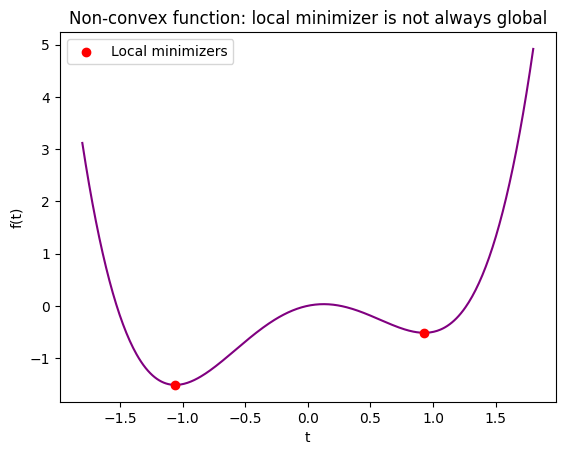

In [13]:
# --- Example 2: non-convex function with two local minimizers ---
h = lambda t: t**4 - 2*t**2 + 0.5*t
t_grid = np.linspace(-1.8, 1.8, 400)

# Convexity inequality fails for some pairs
a_pt, b_pt, tt = -1.0, 1.0, 0.5
print("Convexity check on a = -1, b = 1, t = 0.5:")
print(f"  f(midpoint) = {h(tt*a_pt + (1-tt)*b_pt):.4f}  vs  average of endpoints = {tt*h(a_pt) + (1-tt)*h(b_pt):.4f}")
print("  midpoint value is larger -> NOT convex")

# Different starting points reach different local minimizers
res_left = minimize(lambda v: h(v[0]), x0=[-2.0])
res_right = minimize(lambda v: h(v[0]), x0=[2.0])
print(f"\nStart at -2: local min at t = {res_left.x[0]:.4f}, f = {res_left.fun:.4f}")
print(f"Start at +2: local min at t = {res_right.x[0]:.4f}, f = {res_right.fun:.4f}")
print("Two local minimizers with different values -> only one is the global minimizer.")

plt.plot(t_grid, h(t_grid), color='purple')
plt.scatter([res_left.x[0], res_right.x[0]], [res_left.fun, res_right.fun], color='red', zorder=5,
            label='Local minimizers')
plt.xlabel('t'); plt.ylabel('f(t)')
plt.title('Non-convex function: local minimizer is not always global')
plt.legend()
plt.show()

## 3.3.3 Gradient Descent

Gradient descent is an iterative method for minimizing a differentiable function. Starting from x₀, it repeatedly steps in the direction of steepest descent:

x_{k+1} = x_k - α ∇f(x_k)

where α > 0 is the **step size (learning rate)**.

For the convex quadratic above, the gradient is ∇f(x) = Qx - b, and the iteration converges to the global minimizer as long as α < 2/L, where L is the largest eigenvalue of Q. If α is too large, the iteration diverges.

We'll implement gradient descent from scratch, compare it to the exact solution, show the effect of the step size, and then see how it behaves on the non-convex function.

In [14]:
def gradient_descent(grad, x0, lr, n_iter):
    """Basic gradient descent. Returns the full path of iterates."""
    path = [np.array(x0, dtype=float)]
    for _ in range(n_iter):
        path.append(path[-1] - lr * grad(path[-1]))
    return np.array(path)

grad_quad = lambda v: Q @ v - b

L = np.max(np.linalg.eigvalsh(Q))
print(f"Largest eigenvalue L = {L:.4f}, so convergence requires lr < 2/L = {2/L:.4f}")

# Good step size
path = gradient_descent(grad_quad, x0=[4.0, -3.0], lr=0.1, n_iter=60)
print("\nGradient descent result:", path[-1])
print("Exact minimizer x*:     ", x_star)
print("Close to exact solution:", np.allclose(path[-1], x_star, atol=1e-3))

# Step size too large -> divergence
bad_path = gradient_descent(grad_quad, x0=[4.0, -3.0], lr=0.6, n_iter=50)
print(f"\nWith lr = 0.6 (> 2/L): f at iteration 0 = {f_quad(bad_path[0]):.2f}, "
      f"f at iteration 50 = {f_quad(bad_path[-1]):.2f}  (diverging)")

Largest eigenvalue L = 3.6180, so convergence requires lr < 2/L = 0.5528

Gradient descent result: [0.2003 0.3994]
Exact minimizer x*:      [0.2 0.4]
Close to exact solution: True

With lr = 0.6 (> 2/L): f at iteration 0 = 20.00, f at iteration 50 = 26680780.48  (diverging)


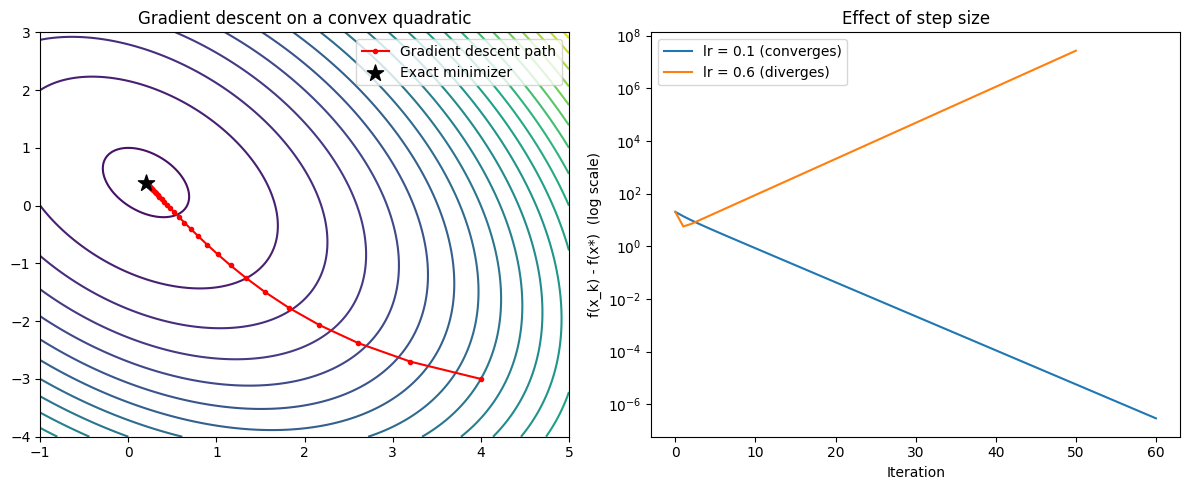

In [15]:
# Contour plot with the descent path, plus loss vs. iteration
xx, yy = np.meshgrid(np.linspace(-1, 5, 200), np.linspace(-4, 3, 200))
zz = 0.5 * (Q[0, 0]*xx**2 + 2*Q[0, 1]*xx*yy + Q[1, 1]*yy**2) - (b[0]*xx + b[1]*yy)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].contour(xx, yy, zz, levels=25, cmap='viridis')
axes[0].plot(path[:, 0], path[:, 1], 'o-', color='red', markersize=3, label='Gradient descent path')
axes[0].scatter(*x_star, color='black', marker='*', s=150, label='Exact minimizer', zorder=5)
axes[0].set_title('Gradient descent on a convex quadratic')
axes[0].legend()

losses = [f_quad(p) - f_quad(x_star) for p in path]
bad_losses = [f_quad(p) - f_quad(x_star) for p in bad_path]
axes[1].semilogy(losses, label='lr = 0.1 (converges)')
axes[1].semilogy(bad_losses, label='lr = 0.6 (diverges)')
axes[1].set_xlabel('Iteration')
axes[1].set_ylabel('f(x_k) - f(x*)  (log scale)')
axes[1].set_title('Effect of step size')
axes[1].legend()

plt.tight_layout()
plt.show()

In [16]:
# Gradient descent on the non-convex function h(t) = t^4 - 2t^2 + 0.5t
grad_h = lambda t: 4*t**3 - 4*t + 0.5

for start in (-2.0, 2.0):
    p = gradient_descent(grad_h, x0=start, lr=0.01, n_iter=1000)
    print(f"Start at {start:+.1f} -> converges to t = {p[-1]:.4f}, f = {h(p[-1]):.4f}")

print("\nOn a non-convex function, gradient descent finds a local minimizer, "
      "and which one depends on the starting point.")

Start at -2.0 -> converges to t = -1.0575, f = -1.5148
Start at +2.0 -> converges to t = 0.9304, f = -0.5167

On a non-convex function, gradient descent finds a local minimizer, and which one depends on the starting point.
